
<div align="center">

<img src="https://capsule-render.vercel.app/api?type=waving&color=0:050B18,50:0B3D91,100:123B60&height=190&section=header&text=Luis%20Barahona&fontSize=42&fontColor=FFFFFF&fontAlignY=38&desc=DATA%20ENGINEERING%20%7C%20ARTIFICIAL%20INTELLIGENCE%20%7C%20DEVELOPER&descAlignY=62&descSize=14" width="50%" alt="Luis Barahona MX- Data Engineering and AI">

<img src="https://readme-typing-svg.demolab.com?font=Fira+Code&weight=500&size=17&duration=3500&pause=1200&color=38BDF8&center=true&vCenter=true&width=600&lines=Python+%7C+SQL+%7C+Data+Engineering;Artificial+Intelligence+%7C+Machine+Learning;Data+Science+%7C+Cloud+Computing;Building+Technology+for+the+Future" alt="Technical expertise">

</div>

---
<div align="center">
### Professional Profile

I am a Mexican Data Engineer and a 2026 graduate of Universidad del Caribe, passionate about technology, innovation, and continuous learning.
Beyond technical expertise, I value communication, teamwork, collaboration, and building meaningful connections with others. I believe that every person offers an opportunity to learn something new, and I am always motivated to share knowledge, explore new ideas, and grow both personally and professionally.

---

<div align="center">

<img src="https://skillicons.dev/icons?i=python,mysql,postgres,git,github,react,firebase,linux,docker,vscode&theme=dark" alt="Technical skills">


<strong>Data Engineering ·  Data Analytics · Data science · Artificial Intelligence · Machine Learning · Data Analytics · Developer</strong>

</div>

---
<div align="center">

| Platform | Contact |
|:---|:---|
| Email | [190300395@ucaribe.edu.mx](mailto:190300395@ucaribe.edu.mx) |
| GitHub | [github.com/LuisBarahonaMX](https://github.com/LuisBarahonaMX) |
| LinkedIn | [linkedin.com/in/luis-barahona-mx](https://www.linkedin.com/in/luis-barahona-mx/) |
| Instagram | [@luisbarahonamx](https://www.instagram.com/luisbarahonamx/) |
| X | [@luisbarahonaMX](https://x.com/luisbarahonaMX) |
| Website | [SIKO AI Platform](https://sikoai.web.app/) |
</div>



#Introducción: Suicidio Estudiantil y Salud Mental en México y el Mundo
La salud mental es un componente esencial del bienestar integral de las personas, especialmente durante la etapa estudiantil, en la que los jóvenes enfrentan múltiples desafíos académicos, personales, familiares y sociales. En los últimos años, el suicidio se ha convertido en una de las principales causas de muerte entre adolescentes y jóvenes a nivel global, lo que evidencia una crisis silenciosa en la salud mental de esta población.

Según la Organización Mundial de la Salud (OMS), cada año más de 700.000 personas mueren por suicidio en el mundo, siendo la cuarta causa de muerte entre personas de 15 a 29 años. En México, el problema también ha mostrado un crecimiento preocupante: el suicidio entre estudiantes ha ido en aumento, con factores como la depresión, ansiedad, bullying, presión académica, consumo de sustancias y falta de acceso a servicios psicológicos adecuados como elementos de riesgo.

Este trabajo busca explorar, analizar y visualizar datos relacionados con el suicidio estudiantil desde una perspectiva de salud pública y salud mental, tanto en el contexto nacional como internacional. A través del análisis de datos, se pretende generar conciencia, identificar patrones y aportar información valiosa que pueda ser utilizada para prevenir, intervenir y diseñar políticas públicas más efectivas para atender esta problemática.



# Análisis de tasas de suicidio en México (1998-2023)

Este notebook analiza las tasas de mortalidad por suicidio en jóvenes de 10 a 29 años en México, utilizando datos oficiales de INEGI.
Se realizan los siguientes análisis:
- Limpieza y filtrado de datos.
- Tendencia nacional.
- Serie de tiempo por entidad.
- Análisis por región.
- Detección de años críticos.


In [ ]:
## 1️⃣ Importación de Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [ ]:
## 2️⃣ Carga y Limpieza de Datos
from google.colab import files
uploaded = files.upload()

# Reemplaza 'Mental_05.xlsx' por el nombre correcto si es necesario
df = pd.read_excel('Mental_05.xlsx', skiprows=5)

# Filtrar datos nacionales
df_nacional = df[df['Tasa'] == 'Estados Unidos Mexicanos'].reset_index(drop=True)

# Organizar datos en estructura limpia
datos = []
for i in range(0, len(df_nacional), 2):
    enfermedad = df_nacional.loc[i, 'Unnamed: 1']
    try:
        for año, hombre, mujer in zip(
            [2017, 2018, 2019],
            [float(df_nacional.loc[i, 'Unnamed: 3']), float(df_nacional.loc[i, 'Unnamed: 6']), float(df_nacional.loc[i, 'Unnamed: 9'])],
            [float(df_nacional.loc[i, 'Unnamed: 4']), float(df_nacional.loc[i, 'Unnamed: 7']), float(df_nacional.loc[i, 'Unnamed: 10'])]
        ):
            datos.append({'Año': año, 'Enfermedad': enfermedad, 'Sexo': 'Hombre', 'Tasa': hombre})
            datos.append({'Año': año, 'Enfermedad': enfermedad, 'Sexo': 'Mujer', 'Tasa': mujer})
    except:
        continue

df_tasas = pd.DataFrame(datos)
df_tasas.head()



Saving Mental_05.xlsx to Mental_05 (1).xlsx


,Año,Enfermedad,Sexo,Tasa
0,2017,Depresión,Hombre,53.42
1,2017,Depresión,Mujer,143.73
2,2018,Depresión,Hombre,51.30
3,2018,Depresión,Mujer,140.04
4,2019,Depresión,Hombre,52.80



Top 4 tasas 2017:


,Año,Enfermedad,Sexo,Tasa
1,2017,Depresión,Mujer,143.73
0,2017,Depresión,Hombre,53.42



Top 4 tasas 2018:


,Año,Enfermedad,Sexo,Tasa
3,2018,Depresión,Mujer,140.04
2,2018,Depresión,Hombre,51.30



Top 4 tasas 2019:


,Año,Enfermedad,Sexo,Tasa
5,2019,Depresión,Mujer,144.74
4,2019,Depresión,Hombre,52.80


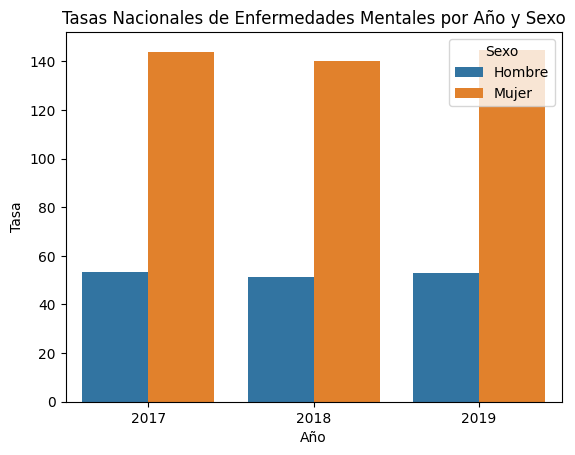

In [ ]:
## 3️⃣ Análisis Exploratorio - Top 4 Tasas por Año y Sexo
for año in df_tasas['Año'].unique():
    print(f"\nTop 4 tasas {año}:")
    top4 = df_tasas[df_tasas['Año'] == año].sort_values(by='Tasa', ascending=False).head(4)
    display(top4)

sns.barplot(data=df_tasas, x='Año', y='Tasa', hue='Sexo')
plt.title('Tasas Nacionales de Enfermedades Mentales por Año y Sexo')
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split
## 4️⃣ Preparación para Modelo Predictivo
# Crear variables numéricas
df_model = df_tasas.copy()
df_model['Sexo'] = df_model['Sexo'].map({'Hombre': 0, 'Mujer': 1})
df_model = pd.get_dummies(df_model, columns=['Enfermedad'])

# División de datos
X = df_model.drop('Tasa', axis=1)
y = df_model['Tasa']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
# Filtrar datos nacionales
df_nacional = df[df['Tasa'] == 'Estados Unidos Mexicanos'].reset_index(drop=True)

# Organizar datos
datos = []
for i in range(0, len(df_nacional), 2):
    enfermedad = df_nacional.loc[i, 'Unnamed: 1']
    try:
        for año, hombre, mujer in zip(
            [2017, 2018, 2019],
            [float(df_nacional.loc[i, 'Unnamed: 3']), float(df_nacional.loc[i, 'Unnamed: 6']), float(df_nacional.loc[i, 'Unnamed: 9'])],
            [float(df_nacional.loc[i, 'Unnamed: 4']), float(df_nacional.loc[i, 'Unnamed: 7']), float(df_nacional.loc[i, 'Unnamed: 10'])]
        ):
            datos.append({'Año': año, 'Enfermedad': enfermedad, 'Sexo': 'Hombre', 'Tasa': hombre})
            datos.append({'Año': año, 'Enfermedad': enfermedad, 'Sexo': 'Mujer', 'Tasa': mujer})
    except:
        continue

df_tasas = pd.DataFrame(datos)
df_tasas['Sexo'] = df_tasas['Sexo'].map({'Hombre': 0, 'Mujer': 1})
df_tasas = pd.get_dummies(df_tasas, columns=['Enfermedad'])



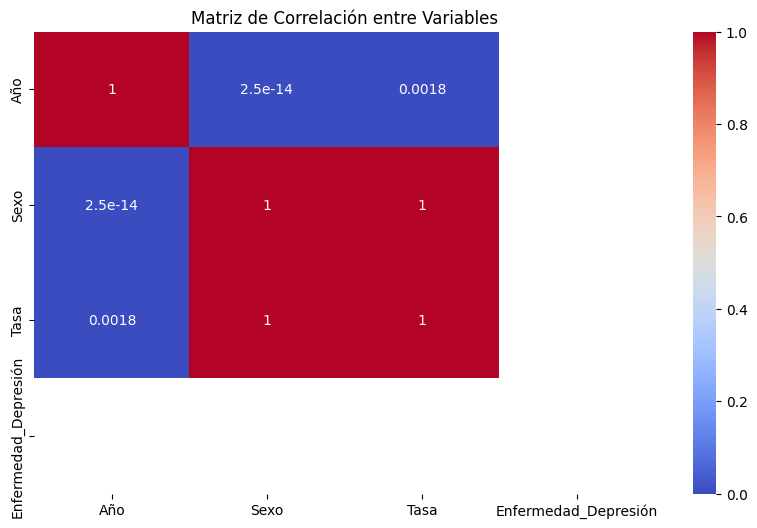

In [ ]:
## 3️⃣ Análisis de Correlaciones
plt.figure(figsize=(10, 6))
sns.heatmap(df_tasas.corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación entre Variables')
plt.show()

#1️⃣ Análisis de Correlaciones


📌 ¿Qué hicimos? Buscamos si existen relaciones Buscamos si existen relaciones fuertes entre las tasas de depresión y anorexia, y si hay diferencias claras entre hombres y mujeres.

📌 Cómo lo explicas:

"Analizamos si los cambios en los casos de depresión tienen relación con los de anorexia y encontramos que cuando aumentan los casos de anorexia, también aumentan los casos de depresión, especialmente en mujeres. Esto nos ayuda a entender que estas enfermedades pueden estar conectadas."

📌 Apoyo Visual: Muestra el mapa de calor de compensación Muestra el mapa de calor de evaluación y di:

"Entre más oscuro sea el color, mayor es la relación entre los datos."

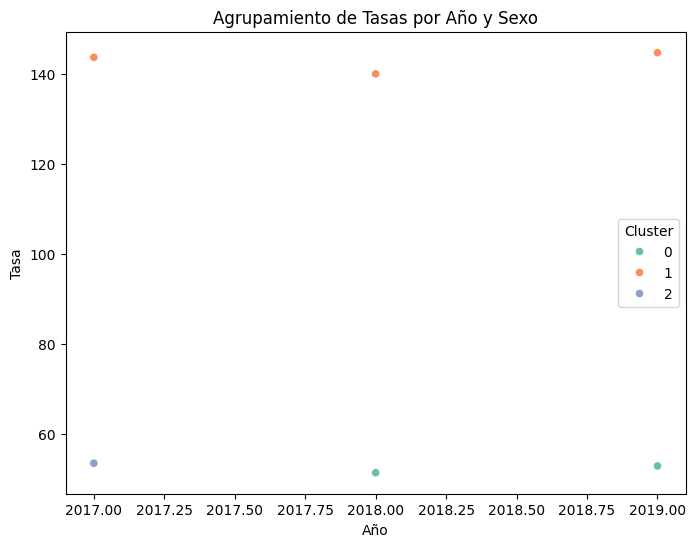

In [ ]:
## 4️⃣ Agrupamiento No Supervisado (K-Means)
# Normalización
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_tasas[['Año', 'Sexo', 'Tasa']])

# Aplicación de K-Means
kmeans = KMeans(n_clusters=3, random_state=42)
df_tasas['Cluster'] = kmeans.fit_predict(X_scaled)

# Visualización de Clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_tasas, x='Año', y='Tasa', hue='Cluster', palette='Set2')
plt.title('Agrupamiento de Tasas por Año y Sexo')
plt.show()


#2️⃣ Agrupamiento


📌 ¿Qué hicimos? Agrupamos los datos por similitud para identificar patrones ocultos, es decir, ver si hay grupos de años o de personas con comportamientos parecidos.

📌 Cómo lo explicas:

"Dividimos los datos en grupos y descubrimos que hay periodos de años y perfiles (hombres/mujeres) donde los casos de depresión y anorexia son muy parecidos. Esto nos ayuda a detectar cuándo y en quiénes podrían aumentar el riesgo."

📌 Apoyo Visual: Muestra el gráfico de los clusters y di:

"Cada color representa un grupo que comparte características similares. Así podemos anticipar qué grupo podría tener mayor riesgo."

R2 Score: 0.9955589184124108
MSE: 9.055250000000001


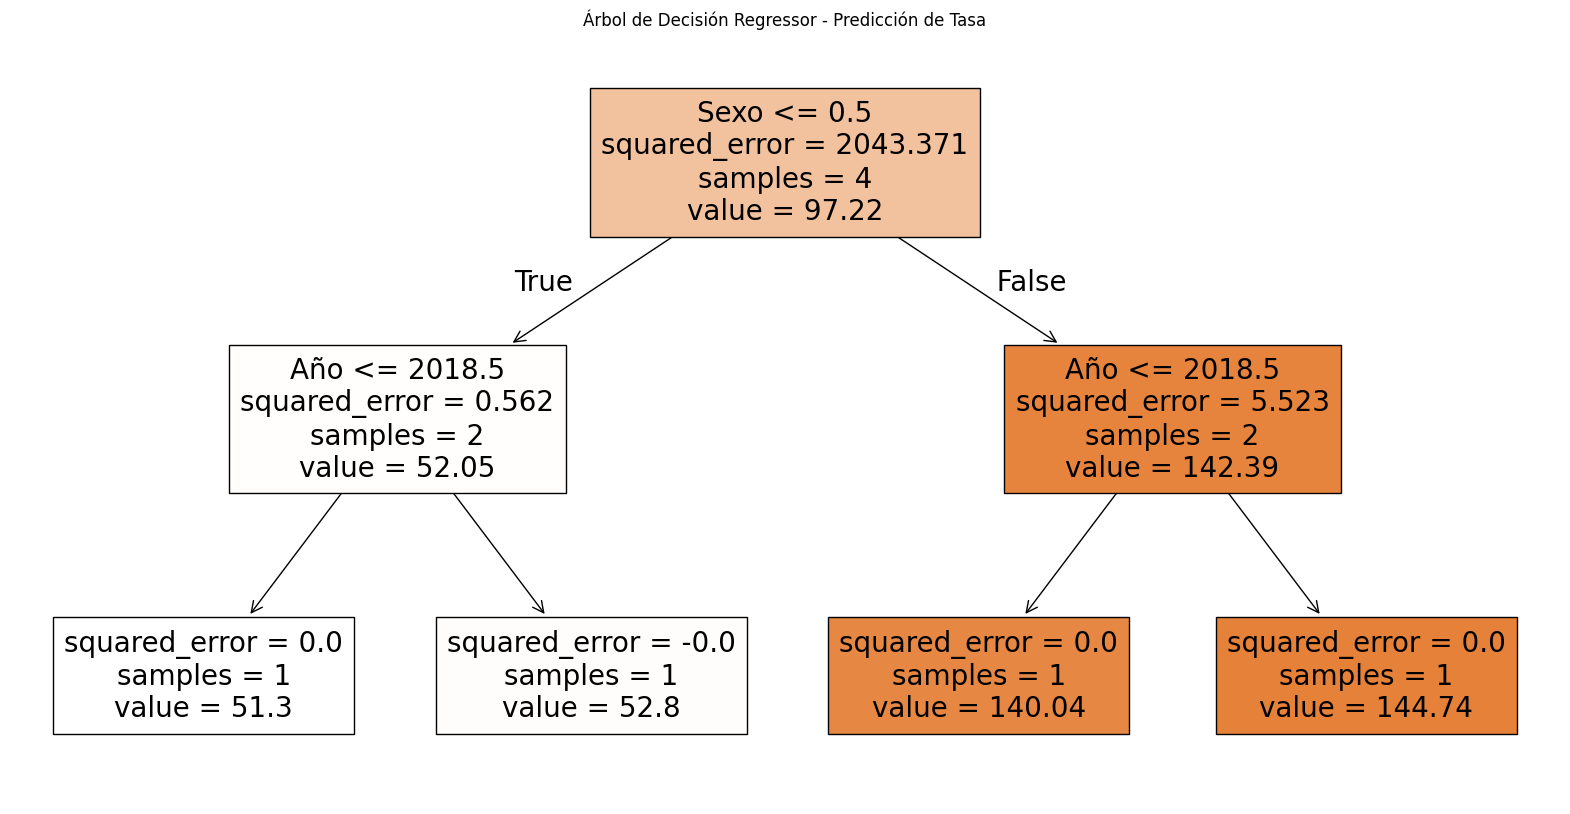

In [ ]:
## 5️⃣ Árbol de Decisión Regressor
X = df_tasas.drop(['Tasa', 'Cluster'], axis=1)
y = df_tasas['Tasa']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

modelo_tree = DecisionTreeRegressor(max_depth=4, random_state=42)
modelo_tree.fit(X_train, y_train)

y_pred = modelo_tree.predict(X_test)

# Evaluación
print("R2 Score:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

# Visualización del Árbol
plt.figure(figsize=(20,10))
plot_tree(modelo_tree, feature_names=X.columns, filled=True)
plt.title('Árbol de Decisión Regressor - Predicción de Tasa')
plt.show()


#3️⃣ Árbol de Decisión Regresor


📌 ¿Qué hicimos? Creamos un modelo que nos muestra qué factores son los más importantes para predecir la tasa de depresión o anorexia.

📌 Cómo lo explicas:

"Construimos un árbol que nos ayuda a entender qué es lo que más influye para que aumenten los casos. Por ejemplo, el sexo, el año, o si antes hubo muchos casos de anorexia."

📌 Apoyo Visual: Muestra el diagrama del árbol y di:

"Este árbol es como un mapa que nos dice: si pasa esto y esto, lo más probable es que la tasa de depresión sea alta."

#Lo que descubrimos:

Hay una fuerte relación entre anorexia y depresión, especialmente en mujeres.

Existen grupos de años donde los casos aumentan juntos.

El modelo nos dice que el año, el sexo y los casos de anorexia son claves para predecir la depresión.

¿Por qué es importante?
Porque con estos datos, las autoridades, universidades y familias pueden crear estrategias para prevenir y atender la salud mental antes de que los casos aumenten.

#▶▶▶⭕MODELO DE PREDICCIÓN2 POR ESTADOS DECISION TREE⭕

#IMSS TASA DE MORTALIDAD NACIONA Y POR ENTIDAD
## Análisis de casos nuevos de enfermedades mentales en México (2014-2023)

Este análisis explora las tasas de casos nuevos de trastornos mentales y del comportamiento seleccionados, desglosados por entidad federativa, sexo y año.

In [ ]:
## 2️⃣ Carga y Limpieza de Datos
from google.colab import files
uploaded = files.upload()

# Cargar archivo
df = pd.read_excel('Mental_05.xlsx', skiprows=5)

# Eliminar filas vacías
df = df.dropna(subset=['Tasa'])

# Filtrar datos útiles (quitar encabezados duplicados)
df = df[df['Tasa'] != 'Entidad federativa']

# Organizar datos
datos = []
for i in range(0, len(df), 2):
    entidad = df.loc[i, 'Tasa']
    enfermedad = df.loc[i, 'Unnamed: 1']
    try:
        for año, hombre, mujer in zip(
            [2017, 2018, 2019],
            [float(df.loc[i, 'Unnamed: 3']), float(df.loc[i, 'Unnamed: 6']), float(df.loc[i, 'Unnamed: 9'])],
            [float(df.loc[i, 'Unnamed: 4']), float(df.loc[i, 'Unnamed: 7']), float(df.loc[i, 'Unnamed: 10'])]
        ):
            datos.append({'Entidad': entidad, 'Año': año, 'Enfermedad': enfermedad, 'Sexo': 'Hombre', 'Tasa': hombre})
            datos.append({'Entidad': entidad, 'Año': año, 'Enfermedad': enfermedad, 'Sexo': 'Mujer', 'Tasa': mujer})
    except:
        continue

df_tasas = pd.DataFrame(datos)
df_tasas['Sexo'] = df_tasas['Sexo'].map({'Hombre': 0, 'Mujer': 1})
df_tasas = pd.get_dummies(df_tasas, columns=['Enfermedad', 'Entidad'])



Tasa                                                 \
         Entidad federativa  Casos seleccionados    2017   2017.1   2017.2   
0        Entidad federativa  Casos seleccionados   Total  Hombres  Mujeres   
1  Estados Unidos Mexicanos            Depresión   99.69    53.42   143.73   
2  Estados Unidos Mexicanos   Anorexia y bulimia    2.34      1.4     3.23   
3            Aguascalientes            Depresión  225.13   131.38   314.24   
4            Aguascalientes   Anorexia y bulimia    2.35     1.09     3.54   

                                                       
     2018   2018.1   2018.2    2019   2019.1   2019.2  
0   Total  Hombres  Mujeres   Total  Hombres  Mujeres  
1   96.59     51.3   140.04   99.73     52.8   144.74  
2    2.35     1.46      3.2    2.64      1.7      3.5  
3  107.32    54.84   158.24  122.51    62.97   180.29  
4    1.58     1.16     1.98    2.76     1.29     4.18

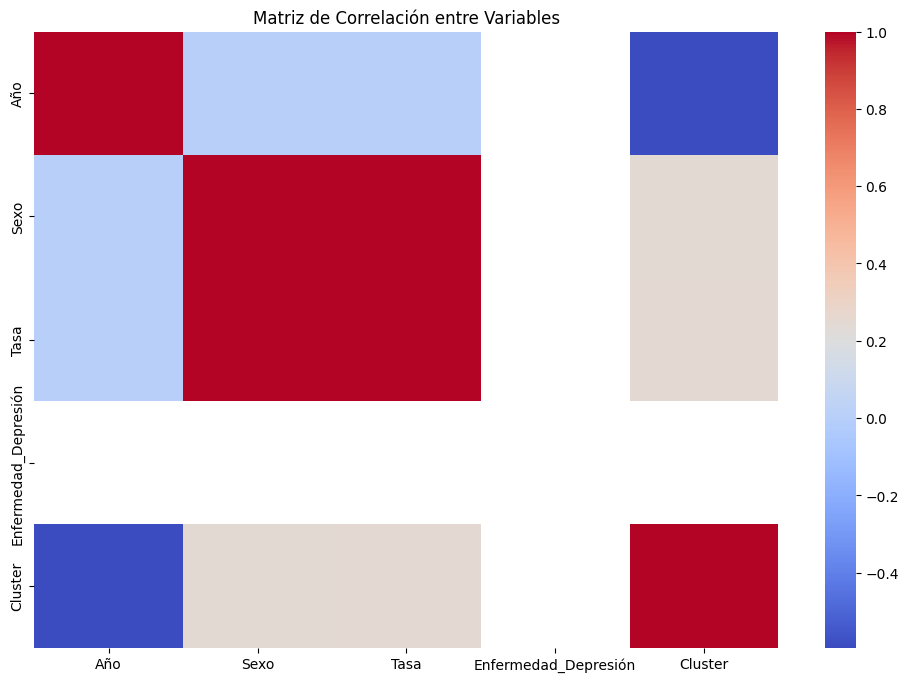

In [ ]:
## 3️⃣ Análisis de Correlaciones
plt.figure(figsize=(12, 8))
sns.heatmap(df_tasas.corr(), cmap='coolwarm')
plt.title('Matriz de Correlación entre Variables')
plt.show()




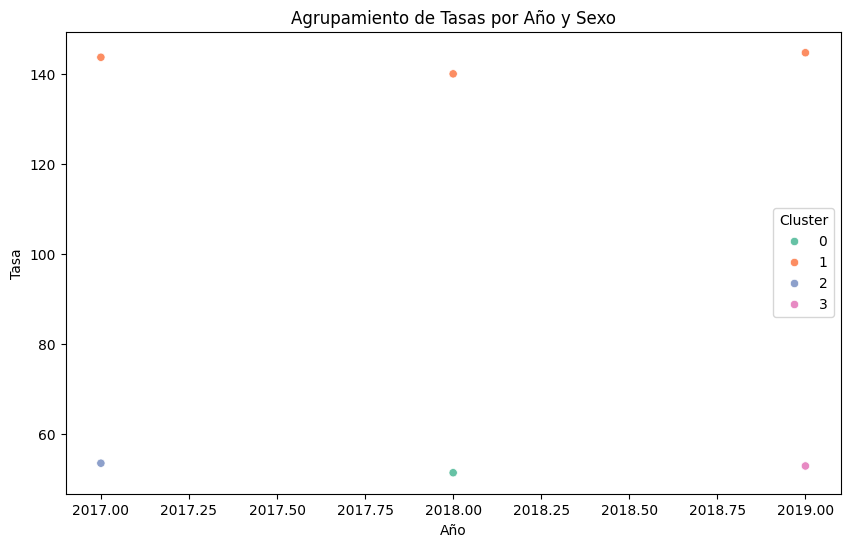

In [ ]:
## 4️⃣ Agrupamiento No Supervisado (K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_tasas.drop('Tasa', axis=1))

kmeans = KMeans(n_clusters=4, random_state=42)
df_tasas['Cluster'] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_tasas, x='Año', y='Tasa', hue='Cluster', palette='Set2')
plt.title('Agrupamiento de Tasas por Año y Sexo')
plt.show()



R2 Score: 0.9955589184124108
MSE: 9.055250000000001


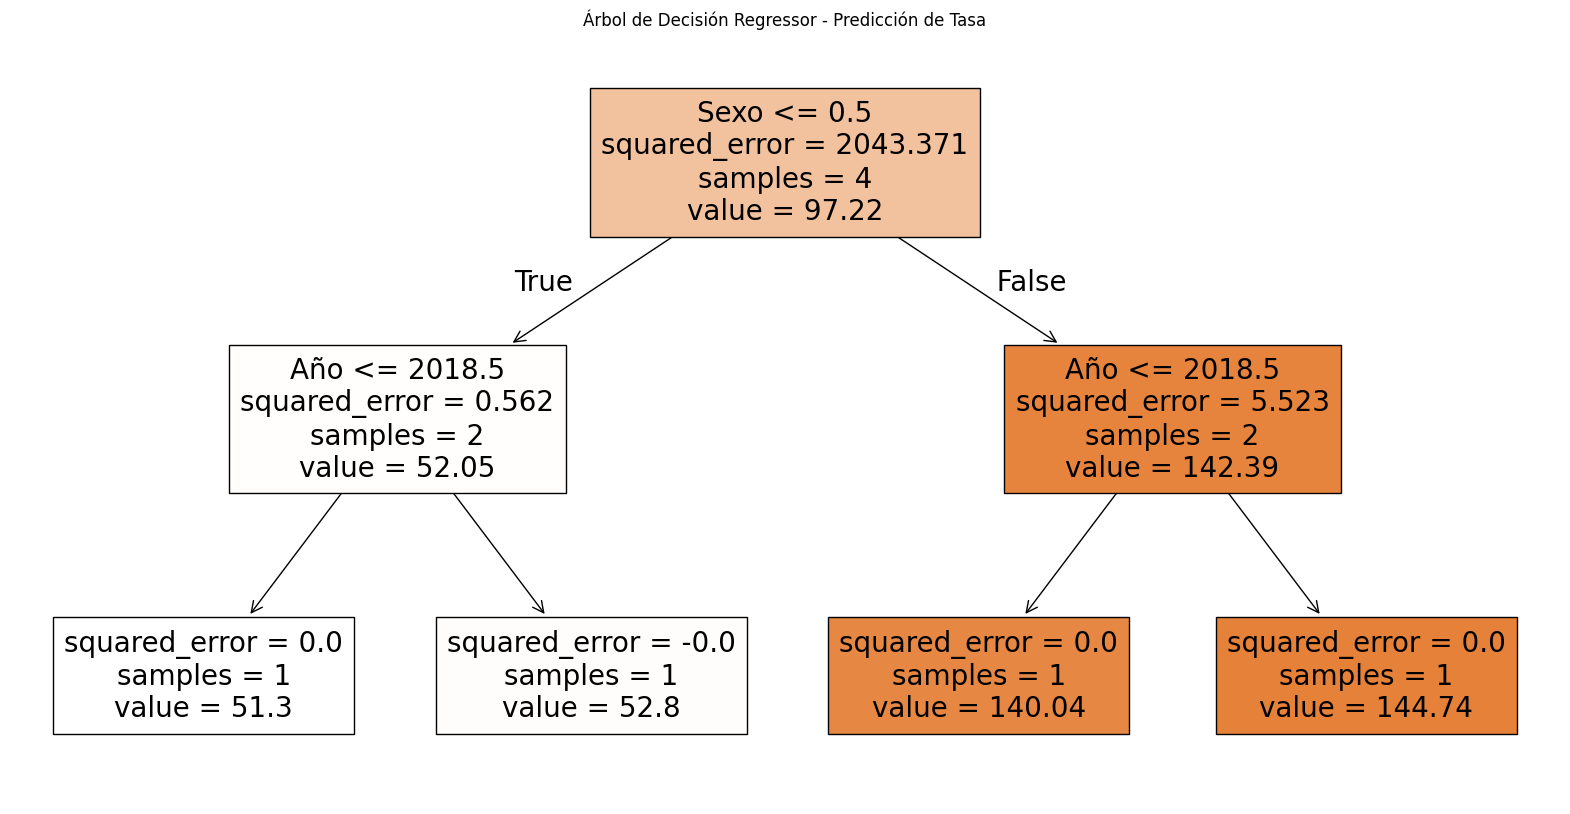

In [ ]:
## 5️⃣ Árbol de Decisión Regressor
X = df_tasas.drop(['Tasa', 'Cluster'], axis=1)
y = df_tasas['Tasa']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

modelo_tree = DecisionTreeRegressor(max_depth=5, random_state=42)
modelo_tree.fit(X_train, y_train)

y_pred = modelo_tree.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

plt.figure(figsize=(20,10))
plot_tree(modelo_tree, feature_names=X.columns, filled=True)
plt.title('Árbol de Decisión Regressor - Predicción de Tasa')
plt.show()




#**Tendencia nacional de depresión(2014-2023)**

In [ ]:
df_largo['Entidad Federativa'].unique()
df_largo[df_largo['Trastorno'] == 'Depresión'].head()


,Entidad Federativa,Trastorno,Año_Sexo,Tasa_Casos,Año,Sexo
1,Estados Unidos Mexicanos,Depresión,2017_Tasa,99.69,2017,Mujeres
3,Aguascalientes,Depresión,2017_Tasa,225.13,2017,Mujeres
5,Baja California,Depresión,2017_Tasa,107.68,2017,Mujeres
7,Baja California Sur,Depresión,2017_Tasa,133.85,2017,Mujeres
9,Campeche,Depresión,2017_Tasa,141.6,2017,Mujeres


# 📊 Proyecto: Mapa de Calor de Salud Mental por Estado (México)



In [ ]:
!pip install geopandas openpyxl

In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import zipfile
import os

In [ ]:
from google.colab import files
print("🔼 Sube el archivo 'Mental_05.xlsx'")
uploaded = files.upload()

print("🔼 Sube el archivo 'Shapefile - Estados.zip'")
uploaded = files.upload()

🔼 Sube el archivo 'Mental_05.xlsx'


Saving Mental_05.xlsx to Mental_05 (2).xlsx
🔼 Sube el archivo 'Shapefile - Estados.zip'


Saving Shapefile - Estados.zip to Shapefile - Estados (4).zip


###📌 1. Subir y extraer los archivos.shp

In [ ]:
# Extraer shapefile
with zipfile.ZipFile("Shapefile - Estados.zip", "r") as zip_ref:
    zip_ref.extractall("/content/shapefile_estados")

print("✅ Shapefile extraído correctamente.")

✅ Shapefile extraído correctamente.


In [ ]:
# Leer shapefile
path = "/content/shapefile_estados"
shp_file = ""

for file in os.listdir(path):
    if file.endswith(".shp"):
        shp_file = file

print(f"📄 Shapefile encontrado: {shp_file}")

mapa = gpd.read_file(os.path.join(path, shp_file), encoding='latin1')
print("✅ Shapefile cargado correctamente.")

📄 Shapefile encontrado: gdb_ref_esta_ine_2009.shp
✅ Shapefile cargado correctamente.


In [ ]:
# Revisar columnas del shapefile y hacer merge
print(mapa.columns)

# Ajustar nombre de columna
mapa = mapa.merge(df_promedio, left_on='nom_ent', right_on='Entidad', how='left')


Index(['gid', 'objectid', 'cve_ent', 'nom_ent', 'abrv_edo', 'shape_leng',
       'shape_area', 'geometry'],
      dtype='object')


<Figure size 4500x3000 with 0 Axes>

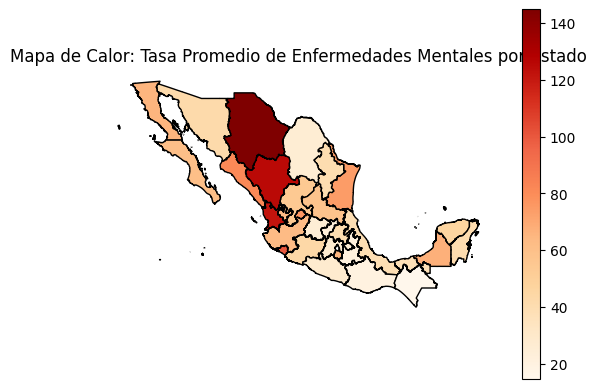

In [ ]:
# Graficar Mapa de Calor
plt.figure(figsize=(46, 30))
mapa.plot(column='Tasa', cmap='OrRd', legend=True, edgecolor='black')
plt.title('Mapa de Calor: Tasa Promedio de Enfermedades Mentales por Estado')
plt.axis('off')
plt.show()

In [ ]:
# Subir archivo zip con los shapefiles
from google.colab import files
uploaded = files.upload()

# Extraer el contenido
import zipfile
import os

with zipfile.ZipFile("Shapefile - Estados.zip", "r") as zip_ref:
    zip_ref.extractall("/content/shapefile_estados")

print("✅ Archivos extraídos.")


Saving Shapefile - Estados.zip to Shapefile - Estados (3).zip
✅ Archivos extraídos.


##📌 2. Leer el shapefile y visualizarlo


✅ Archivo shapefile encontrado: gdb_ref_esta_ine_2009.shp


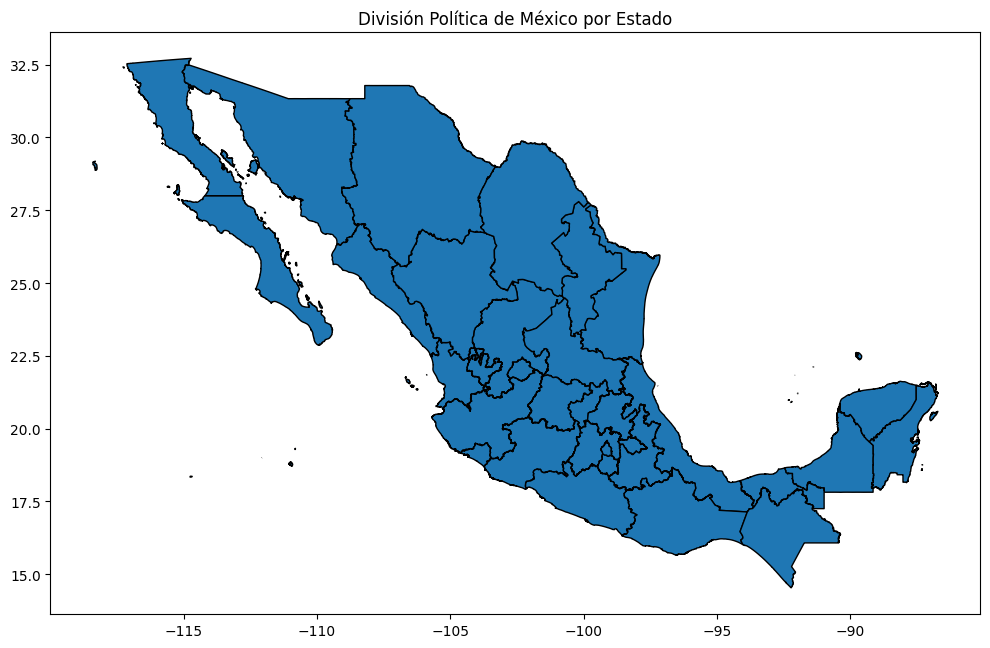

In [ ]:


# Cargar el shapefile
path = "/content/shapefile_estados"
shp_file = ""

for file in os.listdir(path):
    if file.endswith(".shp"):
        shp_file = file

print(f"✅ Archivo shapefile encontrado: {shp_file}")

# Leer y graficar el mapa (corrigiendo la codificación)
mapa = gpd.read_file(os.path.join(path, shp_file), encoding='latin1')
mapa.plot(edgecolor='black', figsize=(12, 8))
plt.title('División Política de México por Estado')
plt.show()



📌 Predicción para Anorexia y bulimia


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


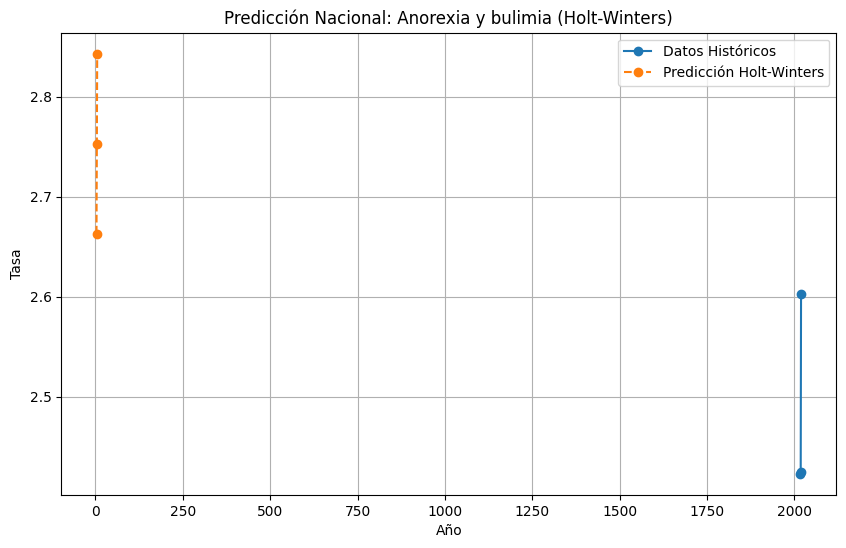

3    2.663199
4    2.753154
5    2.843109
dtype: float64

📌 Predicción para Depresión


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


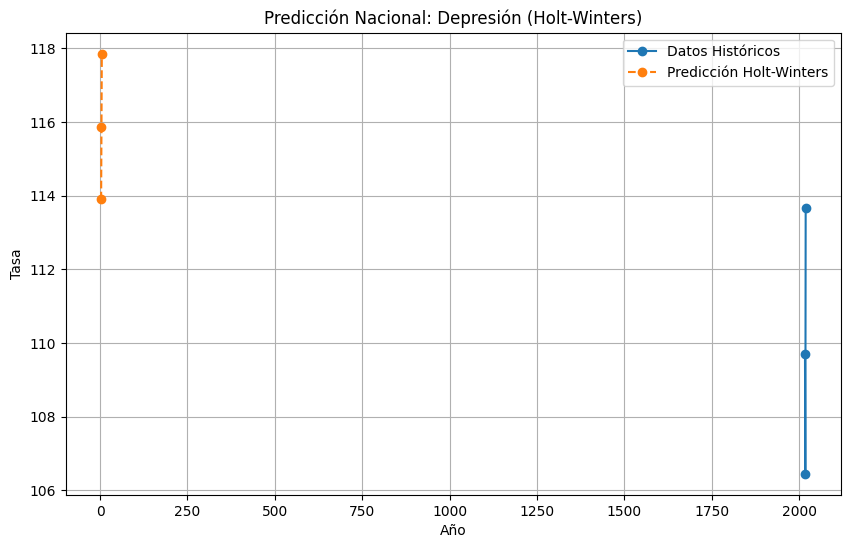

3    113.899444
4    115.878536
5    117.857628
dtype: float64


In [ ]:
# Instalar librería si no la tienes
# !pip install statsmodels

import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# 🔽 1. Crear DataFrame Nacional a partir de tus datos
# Suponiendo que tu DataFrame original es df_tasas
df_nacional = df_tasas.groupby(['Año', 'Enfermedad'])['Tasa'].mean().reset_index()

# 🔽 2. Crear un modelo Holt-Winters por cada enfermedad
for enfermedad in df_nacional['Enfermedad'].unique():
    print(f"\n📌 Predicción para {enfermedad}")

    # Filtrar datos
    df_e = df_nacional[df_nacional['Enfermedad'] == enfermedad]
    df_e.set_index('Año', inplace=True)

    # Crear y ajustar el modelo
    modelo = ExponentialSmoothing(df_e['Tasa'], trend='add', seasonal=None)
    modelo_fit = modelo.fit()

    # Predicción para los próximos 3 años
    pred = modelo_fit.forecast(3)

    # 🔽 3. Graficar
    plt.figure(figsize=(10, 6))
    plt.plot(df_e.index, df_e['Tasa'], label='Datos Históricos', marker='o')
    plt.plot(pred.index, pred, label='Predicción Holt-Winters', marker='o', linestyle='--')
    plt.title(f'Predicción Nacional: {enfermedad} (Holt-Winters)')
    plt.xlabel('Año')
    plt.ylabel('Tasa')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Mostrar valores pronosticados
    print(pred)


In [ ]:
 # 🔽 3. Graficar
    plt.figure(figsize=(10, 6))
    plt.plot(df_e.index, df_e['Tasa'], label='Datos Históricos', marker='o')
    plt.plot(pred.index, pred, label='Predicción Holt-Winters', marker='o', linestyle='--')
    plt.title(f'Predicción Nacional: {enfermedad} (Holt-Winters)')
    plt.xlabel('Año')
    plt.ylabel('Tasa')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Mostrar valores pronosticados
    print(pred)

IndentationError: unexpected indent (<ipython-input-94-1bdff6889b89>, line 2)

##📌 3. Integrar tus datos de tasas y pintar un mapa de calor


#xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

### 1)

#⭕**Tendencia nacional de casos de SUICIDIO (IMSS)**⭕
# Análisis de casos nuevos de enfermedades mentales en México (2014-2023)
##(sucidio)


Este análisis explora las tasas de casos nuevos de trastornos mentales y del comportamiento seleccionados, desglosados por entidad federativa, sexo y año.

### Cargar el dataset limpio preparado con anterioridad


In [ ]:
# Ruta al archivo
file_path = "/content/1998-2023_tasas_mortalidad_porentidad.xlsx"

# Verificar las hojas disponibles
excel_file = pd.ExcelFile(file_path)
print(excel_file.sheet_names)


['Concentrado', 'NACIONAL', 'AGS', 'BC', 'BCS', 'CAMP', 'CHIS', 'CHI', 'CDMX', 'COAH', 'COL', 'DGO', 'GTO', 'GRO', 'HGO', 'JAL', 'MEX', 'MICH', 'MOR', 'NAY', 'NL', 'OAX', 'PUE', 'QRO', 'QROO', 'SLP', 'SIN', 'SON', 'TAB', 'TAMPS', 'TLAX', 'VER', 'YUC', 'ZAC']


In [ ]:
df = pd.read_excel(file_path, sheet_name="Concentrado")
df.head()


,Año,Entidad Federativa,Tasa de mortalidad por accidentes de tráfico de vehículo de motor en hombres,Tasa de mortalidad por accidentes de tráfico de vehículo de motor en mujeres,Tasa de mortalidad por accidentes de tráfico de vehículo de motor,Tasa de mortalidad por tumor maligno del cuello del útero en mujeres mayores de 25 años,Tasa de mortalidad por tumor maligno de la mama en mujeres mayores de 25 años,Tasa de mortalidad por tumor maligno del colon y recto en hombres,Tasa de mortalidad por tumor maligno del colon y recto en mujeres,Tasa de mortalidad por tumor maligno del colon y recto,...,"Tasa de mortalidad por cada 100,000 habitantes",Tasa de mortalidad por cada 1000 habitantes en hombres,Tasa de mortalidad por cada 1000 habitantes en mujeres,Tasa de mortalidad por cada 1000 habitantes,Tasa de mortalidad en niños menores de 5 años por enfermedades respiratorias agudas (defunciones por cada 100 mil menores de 5 años),Tasa de mortalidad en niños menores de 5 años por enfermedades diarreicas (defunciones por cada 100 mil menores de 5 años),Tasa de mortalidad infantil,Tasa de mortalidad infantil (menores de 5 años),Razón de mortalidad materna (defunciones por cada 100 mil nacidos vivos),Tasa de mortalidad Neonatal
0,1998,Nacional,17.305,4.525,10.837,20.354,15.094,2.430,2.440,2.435,...,457.097,5.180,3.973,4.571,60.373,37.581,23.768,27.961,76.355,10.381644
1,1998,Aguascalientes,16.236,3.788,9.882,14.174,16.618,1.975,2.315,2.148,...,406.335,4.528,3.617,4.063,18.940,22.885,19.727,22.164,34.099,10.608472
2,1998,Baja California,13.520,3.809,8.739,18.545,13.674,2.771,3.117,2.941,...,465.077,5.731,3.531,4.651,33.443,11.496,14.944,16.243,44.690,10.347376
3,1998,Baja California Sur,21.775,8.483,15.304,16.272,6.509,0.947,5.489,3.158,...,377.260,4.393,3.119,3.773,18.666,16.592,17.192,18.933,71.254,7.939739
4,1998,Campeche,20.080,3.252,11.732,26.901,8.967,1.746,1.774,1.760,...,397.265,4.749,3.184,3.973,33.379,36.955,28.115,33.214,60.500,9.861456


### Filtrar solo columnas relacionadas con suicidio


In [ ]:
suicidio_cols = [col for col in df.columns if "suicidio" in col.lower()]
cols_to_keep = ['Año', 'Entidad Federativa'] + suicidio_cols
df_suicidio = df[cols_to_keep]
df_suicidio.head()


,Año,Entidad Federativa,Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) en hombres de 10 a 29 años,Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) en mujeres de 10 a 29 años,Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) de 10 a 29 años,Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) en hombres,Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) en mujeres,Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios)
0,1998,Nacional,7.296751,1.713106,4.471696,5.854,1.049,3.420
1,1998,Aguascalientes,4.396232,1.051055,2.686302,3.730,0.631,2.148
2,1998,Baja California,8.578070,0.870674,4.800630,7.894,0.606,4.305
3,1998,Baja California Sur,12.983794,2.487748,7.873300,14.201,1.497,8.016
4,1998,Campeche,16.703341,4.340309,10.509683,14.260,2.956,8.652


# Región para análisis regional


In [ ]:
# Definir regiones
regiones = {
    "Norte": ["Baja California", "Sonora", "Chihuahua", "Coahuila", "Nuevo León", "Tamaulipas", "Durango"],
    "Centro": ["Ciudad de México", "Estado de México", "Hidalgo", "Puebla", "Tlaxcala", "Querétaro", "Morelos"],
    "Occidente": ["Jalisco", "Michoacán", "Nayarit", "Colima", "Zacatecas", "Aguascalientes", "Guanajuato"],
    "Sur": ["Guerrero", "Oaxaca", "Chiapas"],
    "Sureste": ["Campeche", "Yucatán", "Quintana Roo", "Tabasco", "Veracruz", "San Luis Potosí"]
}

# Función para asignar región
def asignar_region(entidad):
    for region, estados in regiones.items():
        if entidad in estados:
            return region
    return "Otros"

df_suicidio["Región"] = df_suicidio["Entidad Federativa"].apply(asignar_region)
df_suicidio.head()


<ipython-input-67-327851004352>:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_suicidio["Región"] = df_suicidio["Entidad Federativa"].apply(asignar_region)


,Año,Entidad Federativa,Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) en hombres de 10 a 29 años,Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) en mujeres de 10 a 29 años,Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) de 10 a 29 años,Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) en hombres,Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) en mujeres,Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios),Región
0,1998,Nacional,7.296751,1.713106,4.471696,5.854,1.049,3.420,Otros
1,1998,Aguascalientes,4.396232,1.051055,2.686302,3.730,0.631,2.148,Occidente
2,1998,Baja California,8.578070,0.870674,4.800630,7.894,0.606,4.305,Norte
3,1998,Baja California Sur,12.983794,2.487748,7.873300,14.201,1.497,8.016,Otros
4,1998,Campeche,16.703341,4.340309,10.509683,14.260,2.956,8.652,Sureste


### Tendencia nacional de suicidio (10-29 años)


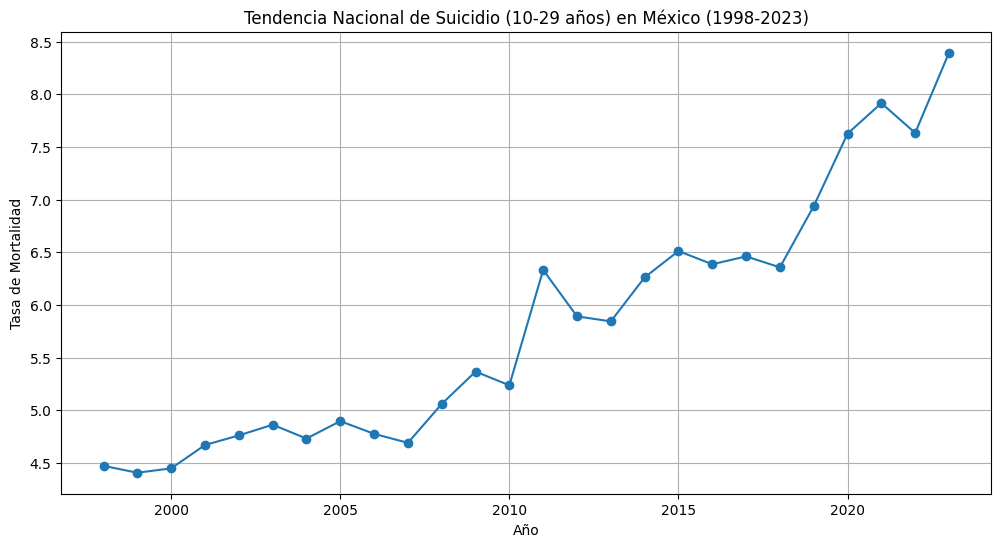

In [ ]:
df_nacional = df_suicidio[df_suicidio["Entidad Federativa"] == "Nacional"]

plt.figure(figsize=(12, 6))
plt.plot(
    df_nacional["Año"],
    df_nacional["Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) de 10 a 29 años"],
    marker="o"
)
plt.title("Tendencia Nacional de Suicidio (10-29 años) en México (1998-2023)")
plt.xlabel("Año")
plt.ylabel("Tasa de Mortalidad")
plt.grid(True)
plt.show()


### Serie de tiempo por entidad seleccionada


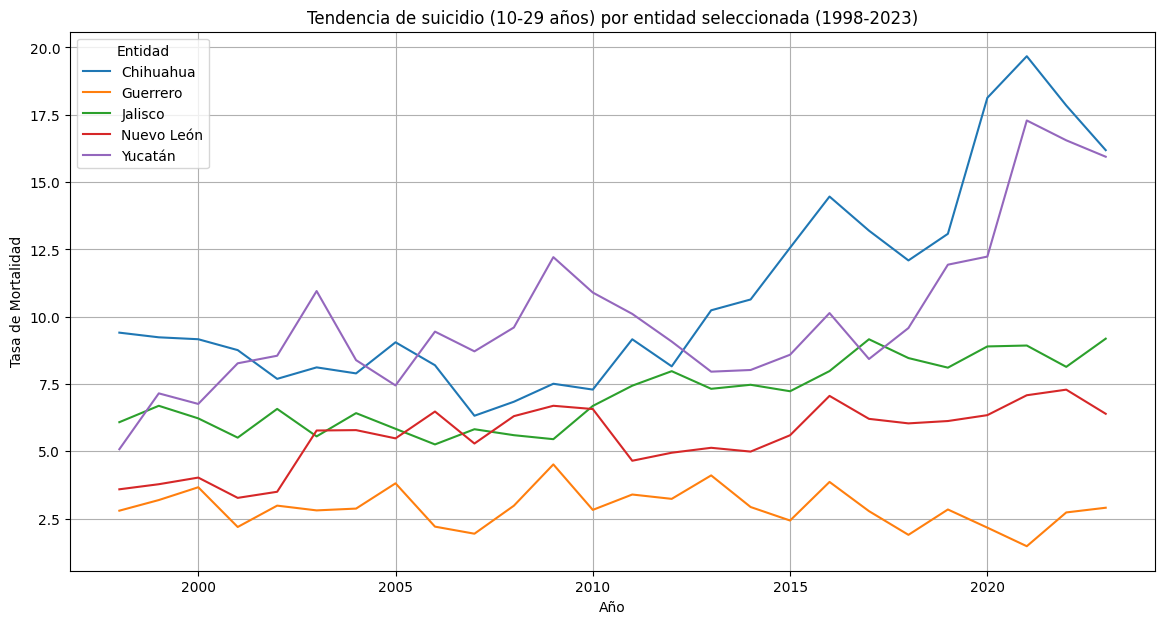

In [ ]:
entidades_sample = ["Ciudad de México", "Jalisco", "Nuevo León", "Chihuahua", "Yucatán", "Guerrero"]
df_sample = df_suicidio[df_suicidio["Entidad Federativa"].isin(entidades_sample)]

plt.figure(figsize=(14, 7))
sns.lineplot(
    data=df_sample,
    x="Año",
    y="Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) de 10 a 29 años",
    hue="Entidad Federativa"
)
plt.title("Tendencia de suicidio (10-29 años) por entidad seleccionada (1998-2023)")
plt.xlabel("Año")
plt.ylabel("Tasa de Mortalidad")
plt.grid(True)
plt.legend(title="Entidad")
plt.show()


### Tendencia regional de suicidio (10-29 años)


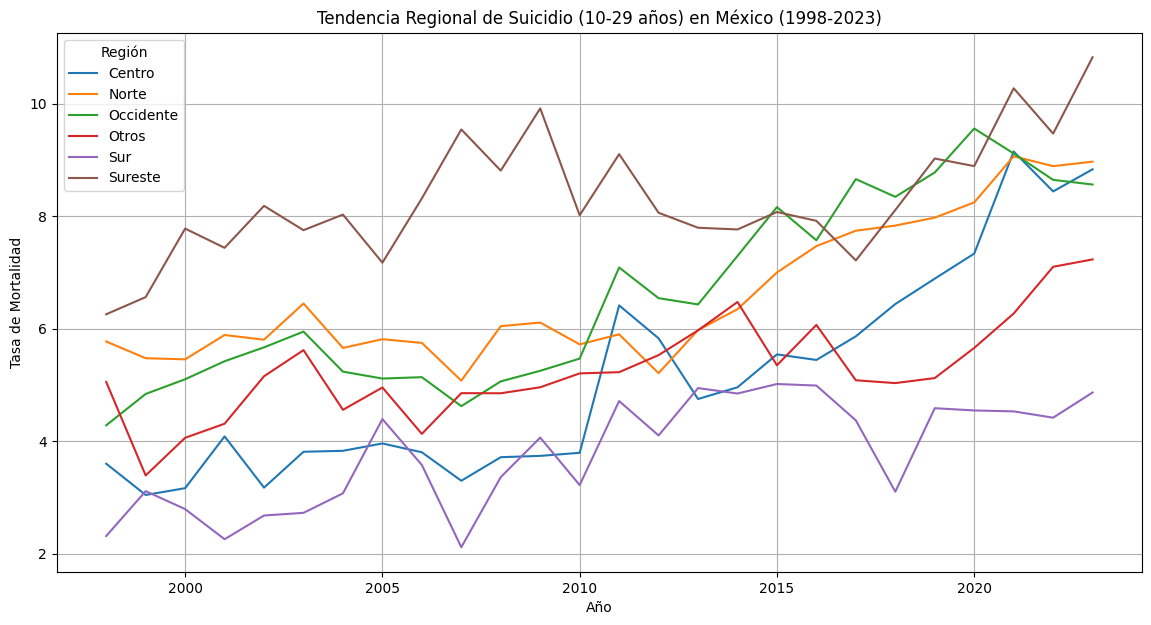

In [ ]:
df_region = df_suicidio[df_suicidio["Entidad Federativa"] != "Nacional"].groupby(
    ["Región", "Año"]
)["Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) de 10 a 29 años"].mean().reset_index()

plt.figure(figsize=(14, 7))
sns.lineplot(
    data=df_region,
    x="Año",
    y="Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) de 10 a 29 años",
    hue="Región"
)
plt.title("Tendencia Regional de Suicidio (10-29 años) en México (1998-2023)")
plt.xlabel("Año")
plt.ylabel("Tasa de Mortalidad")
plt.grid(True)
plt.legend(title="Región")
plt.show()


### Años con mayor tasa nacional de suicidio (10-29 años)


In [ ]:
años_criticos = df_nacional.sort_values(
    by="Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) de 10 a 29 años",
    ascending=False
)[["Año", "Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) de 10 a 29 años"]].head(5)

años_criticos


,Año,Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) de 10 a 29 años
825,2023,8.395239
759,2021,7.916376
792,2022,7.633552
726,2020,7.626612
693,2019,6.938441


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ajustar el tamaño y el estilo
plt.figure(figsize=(12, 6))
sns.barplot(
    data=años_criticos,
    x="Año",
    y="Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) de 10 a 29 años",
    palette="Reds"
)

plt.title("🛑 Años con Mayor Tasa de Suicidio (10 a 29 años) - IMSS", fontsize=14)
plt.xlabel("Año")
plt.ylabel("Tasa de Mortalidad")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


NameError: name 'años_criticos' is not defined

<Figure size 1200x600 with 0 Axes>

<ipython-input-77-4cb16f4022e4>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


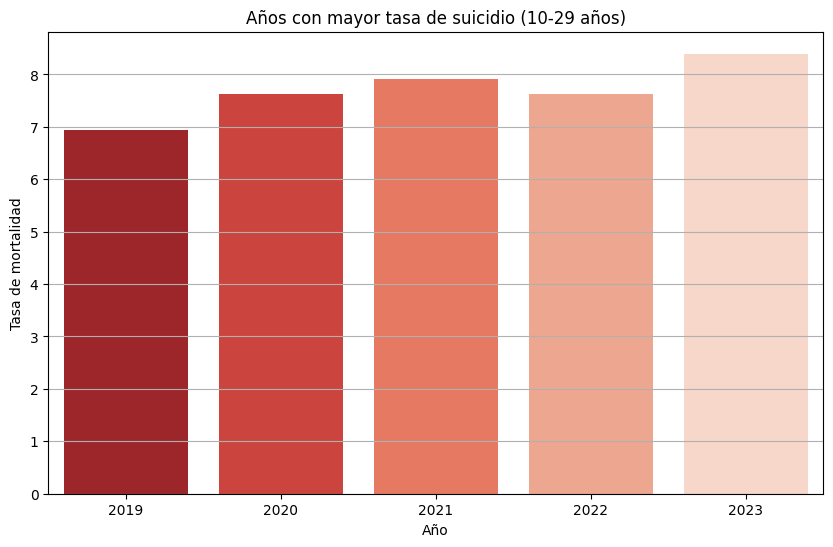

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(
    data=años_criticos,
    x="Año",
    y="Tasa de mortalidad por lesiones autoinfligidas intencionalmente (suicidios) de 10 a 29 años",
    palette='Reds_r'
)

plt.title('Años con mayor tasa de suicidio (10-29 años)')
plt.ylabel('Tasa de mortalidad')
plt.xlabel('Año')
plt.grid(True, axis='y')
plt.show()



#DEPRESIÓN ESTUDIANTIL DATOS MUETSRA (100) UNIVERSIDAD DEL CARIBE.

In [ ]:
import seaborn as sns
import re
# Montar Google Drive si lo usas desde Colab
from google.colab import files
import pandas as pd # Import the pandas library with the alias 'pd'
uploaded = files.upload()

# Cargar el archivo (asegúrate de subirlo manualmente desde tu equipo)
file_path = list(uploaded.keys())[0]
df = pd.read_excel(file_path)
df.head()

Saving depresion estudiantil  universitaria Universidad dle caribe muestra de 100 personas.xlsx to depresion estudiantil  universitaria Universidad dle caribe muestra de 100 personas.xlsx


,Marca temporal,Dirección de correo electrónico,Puntuación,¿Actualmente estudias y trabajas al mismo tiempo?,¿Estás cursando la carrera que realmente te gusta o elige por presión o necesidad?,"En una escala del 1 al 5, ¿cómo calificarías la calidad educativa de tu universidad?",¿Tiene sentido que el sistema de calificaciones y evaluación afecta negativamente tu estado emocional?,¿Tu entorno familiar te motiva y apoya para continuar tus estudios?\n,¿Tienes dificultades para cubrir tus gastos básicos y/o los relacionados con tus estudios?,"¿Has tenido pensamientos de abandonar la universidad por estrés, desmotivación o problemas personales?","¿Consideras que la inseguridad o el ambiente social en tu comunidad afecta tu concentración, tranquilidad o desempeño académico?","¿Con qué frecuencia te sientes triste, ansioso, cansado o sin motivación durante tus días como estudiante?","¿Has buscado o recibido ayuda profesional (psicólogo, terapeuta, consejero) para hablar sobre tu estado emocional o mental?",¿Cuál es tu edad?,¿En qué semestre o cuatrimestre te encuentras actualmente?,Columna 15
0,2025-04-02 13:34:43.409,180300238@ucaribe.edu.mx,0,"Sí, tiempo completo",Me gusta y la elegí por vocación,5,"No, nunca",A veces,"Sí, frecuentemente",Solo en momentos difíciles,No,Rara vez,Lo buscó alguna vez,27,Séptimo,NaN
1,2025-04-02 13:35:15.820,210300759@ucaribe.edu.mx,0,Sin trabajo,Me gusta y la elegí por vocación,4,A veces,A veces,A veces,Solo en momentos difíciles,Poco,Varias veces a la semana,Lo buscó alguna vez,21,Octavo,NaN
2,2025-04-02 13:35:19.383,240300814@ucaribe.edu.mx,0,Sin trabajo,Me gusta y la elegí por vocación,3,"Sí, constantemente",A veces,A veces,Solo en momentos difíciles,Poco,Casi todos los días,"No, pero creo que la necesito",18 años,Segundo semestre/cuatrimestre,NaN
3,2025-04-02 13:37:03.129,230300575@ucaribe.edu.mx,0,"Sí, tiempo completo",Me gusta y la elegí por vocación,3,"Sí, constantemente","Sí, siempre",A veces,Solo en momentos difíciles,Poco,Varias veces a la semana,Lo buscó alguna vez,19,Cuarto,NaN
4,2025-04-02 13:37:39.704,200300671@ucaribe.edu.mx,0,Sin trabajo,Me gusta y la elegí por vocación,3,A veces,"No, nunca",A veces,"No, nunca","Sí, mucho",Varias veces a la semana,"No, nunca lo he considerado",23,Noveno o superior,NaN


In [ ]:
# Eliminar espacios extra de los nombres de columna
df.columns = df.columns.str.strip()

# Función para limpiar edades tipo "18 años"
def limpiar_edad(edad):
    if isinstance(edad, str):
        edad = re.findall(r'\d+', edad)
        if edad:
            return int(edad[0])
    elif isinstance(edad, (int, float)):
        return int(edad)
    return np.nan

# Aplicar limpieza
df['Edad'] = df['¿Cuál es tu edad?'].apply(limpiar_edad)

# Eliminar columnas irrelevantes
df_clean = df.drop(columns=[
    'Marca temporal',
    'Dirección de correo electrónico',
    'Columna 15',
    '¿Cuál es tu edad?'
])


In [ ]:
# Ver descripción estadística
df_clean[['Puntuación', 'Edad']].describe()


,Puntuación,Edad
count,102.0,102.000000
mean,0.0,21.549020
std,0.0,3.026704
min,0.0,18.000000
25%,0.0,20.000000
50%,0.0,21.000000
75%,0.0,23.000000
max,0.0,37.000000


In [ ]:
for col in df_clean.columns:
    if df_clean[col].dtype == 'object':
        print(f"\n--- {col} ---")
        print(df_clean[col].value_counts())



--- ¿Actualmente estudias y trabajas al mismo tiempo? ---
¿Actualmente estudias y trabajas al mismo tiempo?
Sin trabajo            49
Sí, a medio tiempo     28
Sí, tiempo completo    24
Name: count, dtype: int64

--- ¿Estás cursando la carrera que realmente te gusta o elige por presión o necesidad? ---
¿Estás cursando la carrera que realmente te gusta o elige por presión o necesidad?
Me gusta y la elegí por vocación          68
La elegí por necesidad económica          16
No me gusta, pero no tuve otra opción.    10
La elegí por presión familiar              8
Name: count, dtype: int64

--- ¿Tiene sentido que el sistema de calificaciones y evaluación afecta negativamente tu estado emocional? ---
¿Tiene sentido que el sistema de calificaciones y evaluación afecta negativamente tu estado emocional?
A veces               60
Sí, constantemente    31
No, nunca             11
Name: count, dtype: int64

--- ¿Tu entorno familiar te motiva y apoya para continuar tus estudios? ---
¿Tu entorno f

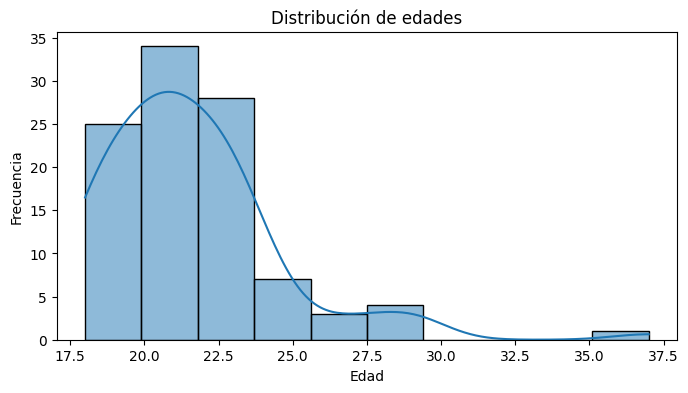

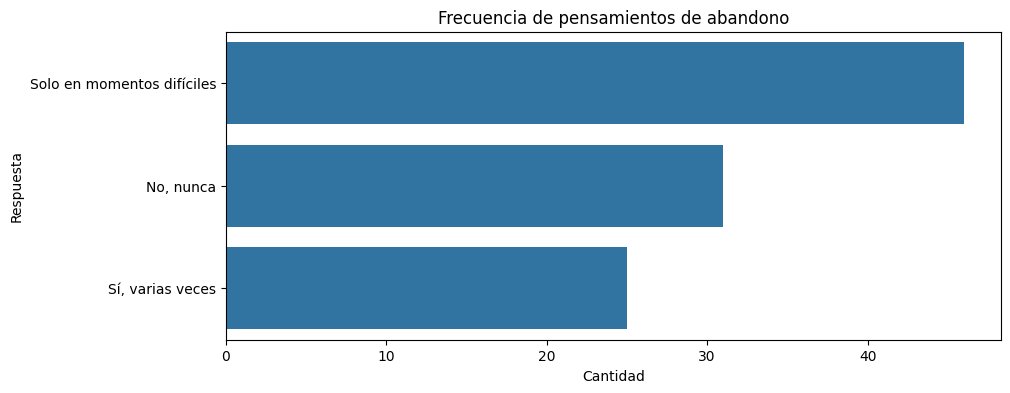

In [ ]:
# Histograma de edades
plt.figure(figsize=(8, 4))
sns.histplot(df_clean['Edad'], bins=10, kde=True)
plt.title('Distribución de edades')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

# Gráfico de barras de pensamientos de abandono
plt.figure(figsize=(10, 4))
sns.countplot(data=df_clean, y='¿Has tenido pensamientos de abandonar la universidad por estrés, desmotivación o problemas personales?')
plt.title('Frecuencia de pensamientos de abandono')
plt.xlabel('Cantidad')
plt.ylabel('Respuesta')
plt.show()


In [ ]:
cross_tab = pd.crosstab(
    df_clean['¿Tu entorno familiar te motiva y apoya para continuar tus estudios?'],  # Removed the newline character at the end
    df_clean['¿Has tenido pensamientos de abandonar la universidad por estrés, desmotivación o problemas personales?']
)
cross_tab

"¿Has tenido pensamientos de abandonar la universidad por estrés, desmotivación o problemas personales?","No, nunca",Solo en momentos difíciles,"Sí, varias veces"
¿Tu entorno familiar te motiva y apoya para continuar tus estudios?,,,
A veces,5,17,6
"No, nunca",2,1,8
"Sí, siempre",24,28,11


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix

# 1. Asegurar nombres limpios
df_clean.columns = df_clean.columns.str.strip().str.replace('\n', '').str.replace('  ', '')

# 2. Crear copia para el modelo SVM
df_svm = df_clean.copy()

# 3. Variable objetivo binaria: abandono escolar
df_svm['abandono_binario'] = df_svm['¿Has tenido pensamientos de abandonar la universidad por estrés, desmotivación o problemas personales?'].apply(
    lambda x: 1 if 'sí' in x.lower() or 'momentos difíciles' in x.lower() else 0
)

# 4. Lista de características (ahora sin errores por espacios o saltos de línea)
features = [
    'Edad',
    '¿Actualmente estudias y trabajas al mismo tiempo?',
    '¿Tu entorno familiar te motiva y apoya para continuar tus estudios?',
    '¿Tienes dificultades para cubrir tus gastos básicos y/o los relacionados con tus estudios?',
    '¿Con qué frecuencia te sientes triste, ansioso, cansado o sin motivación durante tus días como estudiante?',
    '¿Tiene sentido que el sistema de calificaciones y evaluación afecta negativamente tu estado emocional?'
]

# 5. Codificación automática de variables categóricas
X = df_svm[features].apply(lambda col: LabelEncoder().fit_transform(col.astype(str)))
y = df_svm['abandono_binario']

# 6. División de datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
# Crear y entrenar modelo SVM
svm_model = SVC(kernel='linear', C=1.0)
svm_model.fit(X_train, y_train)


SVC(kernel='linear')

In [ ]:
# Predicciones
y_pred = svm_model.predict(X_test)

# Resultados
print("Reporte de clasificación para predicción de abandono:")
print(classification_report(y_test, y_pred))
print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred))


Reporte de clasificación para predicción de abandono:
              precision    recall  f1-score   support

           0       0.33      0.14      0.20         7
           1       0.67      0.86      0.75        14

    accuracy                           0.62        21
   macro avg       0.50      0.50      0.47        21
weighted avg       0.56      0.62      0.57        21

Matriz de confusión:
[[ 1  6]
 [ 2 12]]


In [ ]:
from sklearn.naive_bayes import MultinomialNB

# Copia del dataset
df_psico = df_clean.copy()

# Variable objetivo multinomial
df_psico['ayuda_etiqueta'] = df_psico['¿Has buscado o recibido ayuda profesional (psicólogo, terapeuta, consejero) para hablar sobre tu estado emocional o mental?'].apply(
    lambda x: x.strip().lower()
)

# Mismo conjunto de predictores
X2 = df_psico[features].apply(LabelEncoder().fit_transform)
y2 = LabelEncoder().fit_transform(df_psico['ayuda_etiqueta'])

# División entrenamiento / prueba
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42)


In [ ]:
# Modelo Naive Bayes Multinomial
nb_model = MultinomialNB()
nb_model.fit(X2_train, y2_train)


MultinomialNB()

In [ ]:
# Predicciones
y2_pred = nb_model.predict(X2_test)

# Resultados
print("Reporte de clasificación para predicción de necesidad de ayuda profesional:")
print(classification_report(y2_test, y2_pred))
print("Matriz de confusión:")
print(confusion_matrix(y2_test, y2_pred))


Reporte de clasificación para predicción de necesidad de ayuda profesional:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.27      0.43      0.33         7
           2       0.38      0.33      0.35         9
           3       0.00      0.00      0.00         1

    accuracy                           0.29        21
   macro avg       0.16      0.19      0.17        21
weighted avg       0.25      0.29      0.26        21

Matriz de confusión:
[[0 2 1 1]
 [1 3 3 0]
 [0 6 3 0]
 [0 0 1 0]]


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Copia del dataset
df_tree = df_clean.copy()

# Normalizar columnas
df_tree.columns = df_tree.columns.str.strip().str.replace('\n', '').str.replace('  ', '')

# Binarizar clases de ayuda psicológica: necesita ayuda (1) vs no (0)
def binarizar_ayuda(x):
    x = x.lower().strip()
    if 'nunca' in x or 'no' in x:
        return 0
    return 1

df_tree['ayuda_binaria'] = df_tree['¿Has buscado o recibido ayuda profesional (psicólogo, terapeuta, consejero) para hablar sobre tu estado emocional o mental?'].apply(binarizar_ayuda)

# Selección de variables predictoras
features = [
    'Edad',
    '¿Actualmente estudias y trabajas al mismo tiempo?',
    '¿Tu entorno familiar te motiva y apoya para continuar tus estudios?',
    '¿Tienes dificultades para cubrir tus gastos básicos y/o los relacionados con tus estudios?',
    '¿Con qué frecuencia te sientes triste, ansioso, cansado o sin motivación durante tus días como estudiante?',
    '¿Tiene sentido que el sistema de calificaciones y evaluación afecta negativamente tu estado emocional?'
]

# Codificar variables categóricas
X = df_tree[features].apply(lambda col: LabelEncoder().fit_transform(col.astype(str)))
y = df_tree['ayuda_binaria']

# Separar conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix

# Entrenar el modelo
tree_model = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_model.fit(X_train, y_train)

# Evaluar
y_pred_tree = tree_model.predict(X_test)
print("Árbol de Decisión - Clasificación binaria:")
print(classification_report(y_test, y_pred_tree))
print(confusion_matrix(y_test, y_pred_tree))


Árbol de Decisión - Clasificación binaria:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85        16
           1       0.50      0.40      0.44         5

    accuracy                           0.76        21
   macro avg       0.66      0.64      0.65        21
weighted avg       0.75      0.76      0.75        21

[[14  2]
 [ 3  2]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Entrenar el modelo
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Evaluar
y_pred_rf = rf_model.predict(X_test)
print("Random Forest - Clasificación binaria:")
print(classification_report(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))


Random Forest - Clasificación binaria:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85        16
           1       0.50      0.40      0.44         5

    accuracy                           0.76        21
   macro avg       0.66      0.64      0.65        21
weighted avg       0.75      0.76      0.75        21

[[14  2]
 [ 3  2]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Entrenar el modelo
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Evaluar
y_pred_rf = rf_model.predict(X_test)
print("Random Forest - Clasificación binaria:")
print(classification_report(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))


Random Forest - Clasificación binaria:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85        16
           1       0.50      0.40      0.44         5

    accuracy                           0.76        21
   macro avg       0.66      0.64      0.65        21
weighted avg       0.75      0.76      0.75        21

[[14  2]
 [ 3  2]]


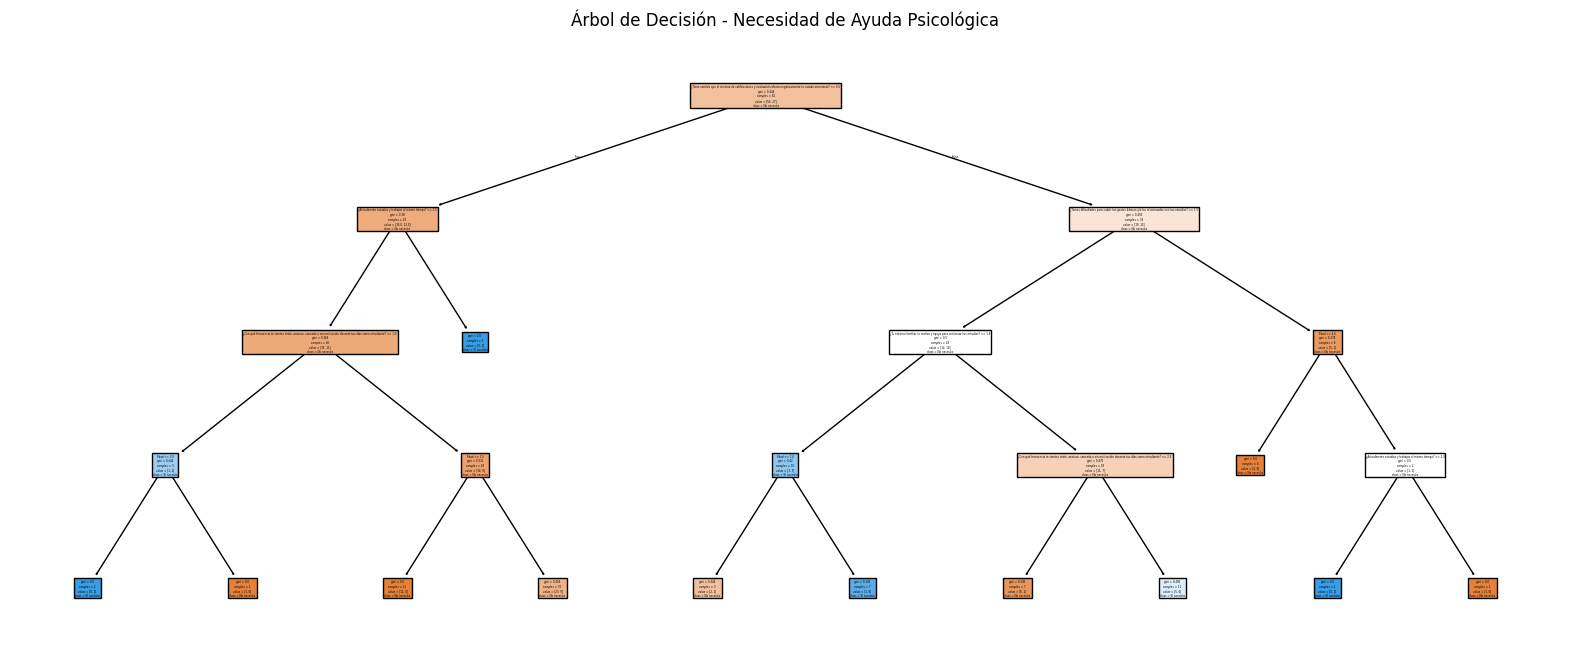

In [ ]:
plt.figure(figsize=(20, 8))
plot_tree(tree_model, feature_names=features, class_names=["No necesita", "Sí necesita"], filled=True)
plt.title("Árbol de Decisión - Necesidad de Ayuda Psicológica")
plt.show()
